In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from tqdm import tqdm

DATA_DIR = Path("../data/raw/images")

In [4]:
corrupt_files = []
valid_image_extensions = {".jpg", ".jpeg", ".png"}

for root, _, files in os.walk(DATA_DIR):
    for file in tqdm(files, desc="Sweeping for corruption"):
        if Path(file).suffix.lower() not in valid_image_extensions:
            continue
            
        file_path = os.path.join(root, file)
        try:
            with Image.open(file_path) as img:
                img.verify()
        except Exception as e:
            print(f"Corrupt file found: {file_path} - {e}")
            corrupt_files.append(file_path)

print(f"Total corrupt files to delete: {len(corrupt_files)}")


Sweeping for corruption: 0it [00:00, ?it/s]
Sweeping for corruption: 100%|██████████| 273/273 [00:04<00:00, 61.10it/s] 

Total corrupt files to delete: 0


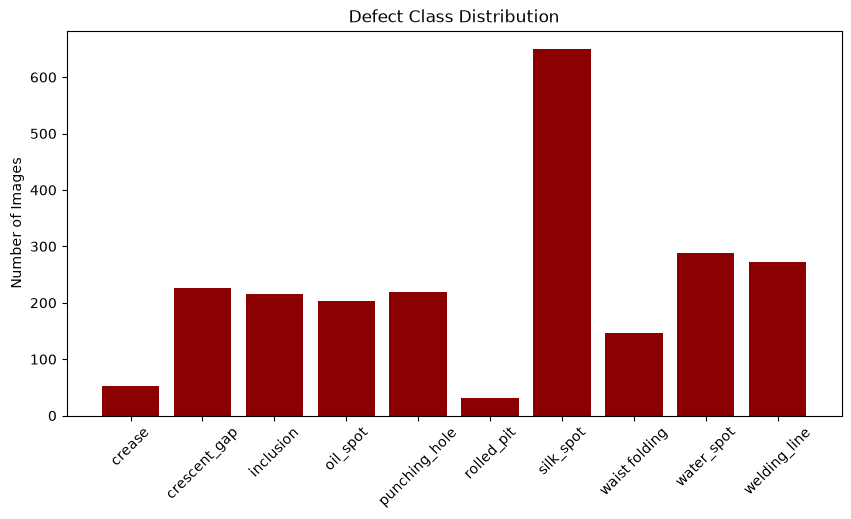

{'crease': 52, 'crescent_gap': 226, 'inclusion': 216, 'oil_spot': 204, 'punching_hole': 219, 'rolled_pit': 31, 'silk_spot': 650, 'waist folding': 146, 'water_spot': 289, 'welding_line': 273}


In [ ]:
class_counts = {}


for class_name in os.listdir(DATA_DIR):
    class_path = DATA_DIR / class_name
    if class_path.is_dir():
        count = len(list(class_path.glob('*.*')))
        class_counts[class_name] = count


plt.figure(figsize=(10, 5))
plt.bar(class_counts.keys(), class_counts.values(), color='darkred')
plt.title("Defect Class Distribution")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

print(class_counts)

Extracting dimensions: 100%|██████████| 2306/2306 [00:34<00:00, 66.08it/s] 


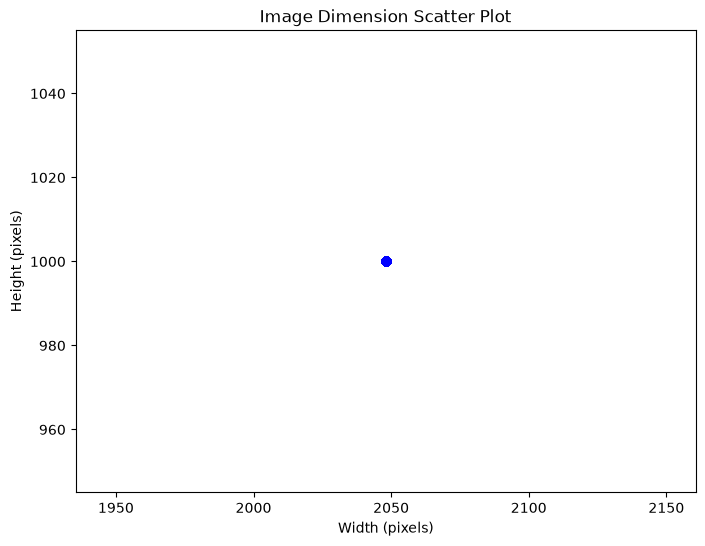

Median Dimensions: 2048.0x1000.0


In [2]:
widths, heights = [], []

all_images = list(DATA_DIR.rglob('*.*'))

for img_path in tqdm(all_images, desc="Extracting dimensions"):
    try:
        with Image.open(img_path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
    except:
        pass

plt.figure(figsize=(8, 6))
plt.scatter(widths, heights, alpha=0.5, c='blue')
plt.title("Image Dimension Scatter Plot")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.show()

print(f"Median Dimensions: {np.median(widths)}x{np.median(heights)}")

In [ ]:
import numpy as np
from PIL import Image
from tqdm import tqdm

pixel_sum = 0.0
pixel_sq_sum = 0.0
total_pixels = 0


for img_path in tqdm(all_images, desc="Calculating Pixel mean and std"):
    try:
        with Image.open(img_path) as img:
            img_gray = img.convert('L') 
            img_array = np.array(img_gray) / 255.0 
            
           
            pixel_sum += np.sum(img_array)
            pixel_sq_sum += np.sum(img_array ** 2)
            total_pixels += img_array.size
    except Exception as e:
        pass


global_mean = pixel_sum / total_pixels
global_std = np.sqrt((pixel_sq_sum / total_pixels) - (global_mean ** 2))

print(f"\nWrite this down for data_loader.py:")
print(f"Mean: [{global_mean:.4f}]")
print(f"Std:  [{global_std:.4f}]")

Calculating Pixel mean and std: 100%|██████████| 2306/2306 [01:11<00:00, 32.36it/s]


Write this down for data_loader.py:
Mean: [0.3361]
Std:  [0.1550]


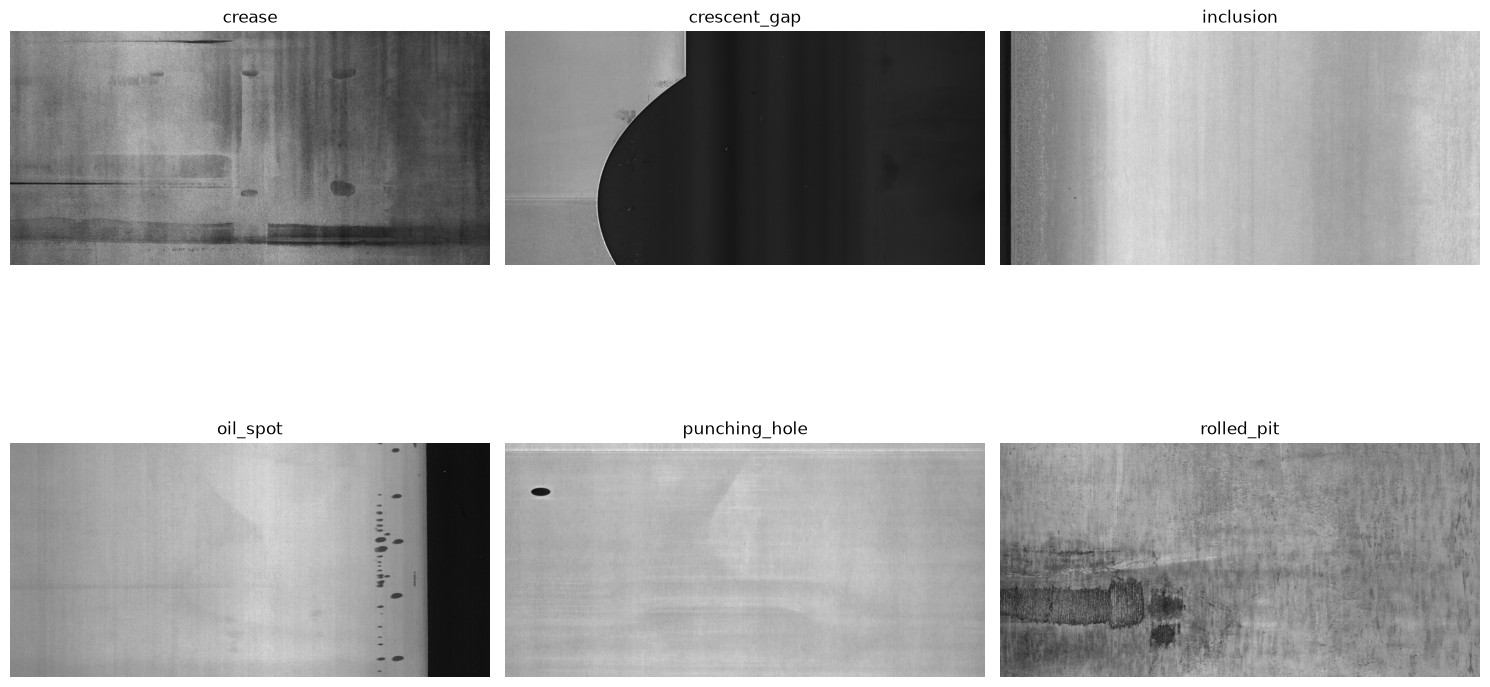

In [ ]:
classes = [d for d in os.listdir(DATA_DIR) if (DATA_DIR / d).is_dir()]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, class_name in enumerate(classes[:6]): 
    class_path = DATA_DIR / class_name
    images = list(class_path.glob('*.*'))
    
    if images:
        random_image = random.choice(images)
        img = Image.open(random_image).convert('L')
        
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(class_name)
        axes[i].axis('off')

plt.tight_layout()
plt.show()